# Inventory Policy Simulation

- **Goal**: Turn the demand forecasts into replenishment decisions, compare policies by simulating 2024 against the demand that actually occurred, test whether the differences are real, and optimise beyond a single service parameter.
- **Inputs**: `outputs/csv/demand_forecasts.csv`, `ratio_quantiles.csv`, `training_error_scale.csv` (`resid_std` and `ratio_std`), `mean_forecast_lookahead.csv` (from the forecasting notebook) and `data/inventory_demand_forecasting.csv` (prices).
- **Outputs** (in `outputs/csv/`): `policy_comparison.csv`, `mc_policy_comparison.csv`, `scenario_sensitivity.csv`, `alpha_q_grid.csv`, `alpha_allocation.csv`, `policy_parameters.csv`, `recommended_reorder_points.csv`; figures in `outputs/figures/`.


## 0. Setup and Assumptions

The dataset contains no cost, lead-time or ordering information, so these are **assumptions**. They are anchored to observable data where possible (unit price) and to common industry ranges otherwise, and each is varied in the sensitivity analysis (Section 5). Conclusions are therefore about the **relative** performance of policies, not absolute savings.

| Parameter | Base value | Sensitivity | Rationale |
|---|---|---|---|
| Unit price *p* | Per-product mean price in the data before 2024-01-06 (≈ 101–106) | none | Daily price is random (10–199) and unrelated to demand, so the mean is a stable anchor |
| Unit cost *c* | 0.65 *p* | 0.80 *p* | Typical retail gross margin of 25–50% |
| Holding cost *h* | 25% of *c* per year, charged on end-of-day stock | 35% | Common rule of thumb is 15–30% (capital, storage, obsolescence) |
| Review period *R* | 1 day (daily review) | 7 days | Data are daily; weekly review is a realistic alternative |
| Lead time *L* | 7 days, deterministic | 3 and 14 days | Within the 60-day forecast horizon |
| Fixed order cost *K* | 80 per order | 300 | Chosen so the EOQ is about 500 units, roughly one week of demand |
| Unmet demand | Lost sales | none | Common in retail; simple and conservative |
| Stockout penalty | Lost margin (*p* − *c*) per unit | + goodwill of 2x margin | |
| Initial stock | Order-up-to level; first 30 days excluded from all metrics | none | Removes the effect of the arbitrary starting point |
| Capacity | None in the base case | inventory-value budget (Section 6) | The data contains no capacity or budget limit, so products are managed independently, except in Section 6 where a budget couples them |
| Products | Same parameters for all | different margins per product (Section 6, illustration only) | The EDA found the five products statistically similar |

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils.py").exists())
sys.path.insert(0, str(ROOT))   # lets `from src.utils import ...` work from notebooks/ or the project root
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.optimize import milp, LinearConstraint, Bounds

from src.utils import load_data, load_output, save_output, save_figure, set_plot_style

set_plot_style()

BASE = dict(L=7, R=1, holding_rate=0.25, cost_ratio=0.65, K=80.0, goodwill=0.0)
WARMUP = 30                                   # days excluded from all metrics
ALPHAS = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995]
N_DRAWS = 20000                               # Monte Carlo draws for lead-time demand
SEED = 42
AF = [round(a, 3) for a in np.arange(0.50, 0.9951, 0.005)]      # fine alpha grid for the allocation model (Section 6)
N_PATHS = 400                                 # simulated demand paths for the policy comparison (Section 3.1)
GRID_PATHS = 100                              # paths for the (alpha, Q) grid and the allocation model (Section 6)
SENS_PATHS = 100                              # paths per scenario in the sensitivity analysis (Section 5)

NAIVE, CLAIRVOYANT = 'Naive (no safety stock)', 'Clairvoyant (perfect foresight)'
CLASSICAL, CVNORMAL, QUANTILE = 'Classical (constant sigma)', 'Normal (CV-scaled sigma)', 'Quantile (multiplicative)'
POLICIES = (CLASSICAL, CVNORMAL, QUANTILE)
KEY = {CLASSICAL: 'classical', CVNORMAL: 'cvnormal', QUANTILE: 'quantile'}
COLORS = {CLASSICAL: '#ef4444', CVNORMAL: '#16a34a', QUANTILE: '#2563eb'}

### 0.1 Load forecasts

The forecasts are out-of-fold: each day's forecast was produced without seeing that day, so replaying actual 2024 demand against them is a fair test.

In [2]:
raw = load_data()
fc = load_output('demand_forecasts').sort_values(['product_id', 'date']).reset_index(drop=True)
ratio_q = load_output('ratio_quantiles')
scale_tbl = load_output('training_error_scale').set_index('fold')
scale, cv = scale_tbl['resid_std'], scale_tbl['ratio_std']   # additive sigma; coefficient of variation of actual / fitted
look = load_output('mean_forecast_lookahead')

PRODUCTS = sorted(fc['product_id'].unique())
FOLDS = sorted(fc['fold'].unique())
HORIZON = int(fc.groupby(['product_id', 'fold']).size().iloc[0])      # days per fold
LOOKAHEAD = int(look.groupby(['fold', 'product_id']).size().max())    # mean-forecast days beyond each fold
T = fc['date'].nunique()

# Every product must cover the same dates in the same order
dates = fc[fc['product_id'] == PRODUCTS[0]]['date'].to_numpy()
assert all((fc[fc['product_id'] == p]['date'].to_numpy() == dates).all() for p in PRODUCTS)

ACT = {p: fc[fc['product_id'] == p]['actual_demand'].to_numpy(float) for p in PRODUCTS}
PROMO = {p: fc[fc['product_id'] == p]['promotion'].to_numpy() for p in PRODUCTS}
MONTH = pd.DatetimeIndex(dates).month.to_numpy()

print(f"{len(PRODUCTS)} products x {T} days ({pd.Timestamp(dates[0]).date()} to {pd.Timestamp(dates[-1]).date()}), "
      f"{len(FOLDS)} folds of {HORIZON} days, {LOOKAHEAD}-day mean-forecast look-ahead")

5 products x 360 days (2024-01-06 to 2024-12-30), 6 folds of 60 days, 21-day mean-forecast look-ahead


In [3]:
# Unit economics from data before the simulation window only
history = raw[raw['date'] < fc['date'].min()]
econ = history.groupby('product_id').agg(price=('price', 'mean'), daily_demand=('demand', 'mean'))

def unit_economics(params):
    e = econ.copy()
    e['cost'] = params['cost_ratio'] * e['price']
    e['h_day'] = params['holding_rate'] * e['cost'] / 365                 # holding cost per unit per day
    e['penalty'] = (e['price'] - e['cost']) * (1 + params['goodwill'])    # cost per unit of lost sales
    e['annual_demand'] = e['daily_demand'] * 365
    e['Q'] = np.ceil(np.sqrt(2 * params['K'] * e['annual_demand'] / (params['holding_rate'] * e['cost'])))   # EOQ
    return e

unit_economics(BASE).round(2)

,price,daily_demand,cost,h_day,penalty,annual_demand,Q
product_id,,,,,,,
A,107.85,72.36,70.10,0.05,37.75,26412.19,492.0
B,104.17,66.81,67.71,0.05,36.46,24386.93,481.0
C,101.81,67.05,66.18,0.05,35.63,24474.73,487.0
D,106.50,71.76,69.23,0.05,37.28,26194.18,493.0
E,104.07,68.13,67.65,0.05,36.43,24867.35,486.0


## 1. Demand Over the Protection Interval

A replenishment order placed today protects against demand until the *next* order could arrive: the protection interval is *L* + *R* days. The forecast file contains quantiles of a **single day**, and they cannot be added up: the chance that *every* day is simultaneously at its P90 is tiny. Because errors are independent across days (residual autocorrelation ≈ 0 in the forecasting notebook), the relative spread of a total over *n* days shrinks roughly like 1/√*n*.

We therefore simulate: draw the daily noise ratio (`actual / fitted`) from the fold's training distribution, multiply by the daily mean forecast, sum over the interval, and take quantiles of the total.

In [4]:
def mean_blocks(product):
    """Per fold: mean forecast for the test days followed by the look-ahead days (same fold's model)."""
    blocks = {}
    for k in FOLDS:
        test_mu = fc[(fc['product_id'] == product) & (fc['fold'] == k)]['demand_mean'].to_numpy()
        ext_mu = look[(look['product_id'] == product) & (look['fold'] == k)].sort_values('date')['demand_mean'].to_numpy()
        if len(ext_mu) < LOOKAHEAD:   # last fold: the data end, so carry the recent average forward
            ext_mu = np.concatenate([ext_mu, np.full(LOOKAHEAD - len(ext_mu), test_mu[-7:].mean())])
        blocks[k] = np.concatenate([test_mu, ext_mu])
    return blocks

MU = {p: mean_blocks(p) for p in PRODUCTS}

def window_sums(arr, n):
    """Sum of the next n values from each position (shorter at the end of the array)."""
    return pd.Series(arr[::-1]).rolling(n, min_periods=1).sum().to_numpy()[::-1]

def protection_stats(L, R, alphas=None):
    """For every product and day: mean demand over the protection interval, and reorder-point candidates."""
    alphas = ALPHAS if alphas is None else alphas
    n = L + R
    rng = np.random.default_rng(SEED)
    z = norm.ppf(alphas)[:, None]
    parts = {p: {'mean': [], 'quantile': [], 'classical': [], 'cvnormal': []} for p in PRODUCTS}
    for k in FOLDS:
        lv = ratio_q[ratio_q['fold'] == k].sort_values('level')
        draws = np.interp(rng.random((N_DRAWS, n)), lv['level'].to_numpy(), lv['ratio'].to_numpy())   # noise ratios
        for p in PRODUCTS:
            W = np.lib.stride_tricks.sliding_window_view(MU[p][k], n)[:HORIZON]      # (days, n) mean forecasts
            mean_sum = W.sum(axis=1)
            parts[p]['mean'].append(mean_sum)
            parts[p]['quantile'].append(np.quantile(draws @ W.T, alphas, axis=0))     # (alphas, days)
            parts[p]['classical'].append(mean_sum + z * scale[k] * np.sqrt(n))
            parts[p]['cvnormal'].append(mean_sum + z * cv[k] * np.sqrt((W ** 2).sum(axis=1)))   # sd of a sum of independent days with sd_t = CV x mean_t
    return {p: {'mean': np.concatenate(v['mean']),
                'quantile': np.concatenate(v['quantile'], axis=1),
                'classical': np.concatenate(v['classical'], axis=1),
                'cvnormal': np.concatenate(v['cvnormal'], axis=1),
                'clairvoyant': window_sums(ACT[p], n)} for p, v in parts.items()}

In [5]:
# Why daily quantiles cannot be added up: compare, over windows inside a fold,
# (a) the sum of daily P90s and (b) the simulated P90 of the total, both relative to the mean total.
a90 = ALPHAS.index(0.90)
in_fold_day = np.arange(T) % HORIZON
rows = []
for L in (3, 7, 14):
    n = L + 1
    st = protection_stats(L, 1)
    ok = in_fold_day + n <= HORIZON                                   # windows fully inside one fold
    naive_ratio, sim_ratio = [], []
    for p in PRODUCTS:
        p90_daily = fc[fc['product_id'] == p]['demand_p90'].to_numpy()
        naive_ratio.append((window_sums(p90_daily, n) / st[p]['mean'])[ok])
        sim_ratio.append((st[p]['quantile'][a90] / st[p]['mean'])[ok])
    rows.append({'interval (days)': n,
                 'sum of daily P90 / mean': np.median(np.concatenate(naive_ratio)),
                 'simulated P90 of total / mean': np.median(np.concatenate(sim_ratio))})
interval_table = pd.DataFrame(rows).set_index('interval (days)')
interval_table['implied safety stock overstated by'] = (
    (interval_table['sum of daily P90 / mean'] - 1) / (interval_table['simulated P90 of total / mean'] - 1))
interval_table.round(2)

,sum of daily P90 / mean,simulated P90 of total / mean,implied safety stock overstated by
interval (days),,,
4,1.55,1.27,2.04
8,1.55,1.19,2.88
15,1.55,1.14,3.96


**Observations**
- Adding up daily P90s gives about 1.55x the mean for any interval length, but the simulated P90 of the total is only 1.27x (4 days), 1.19x (8 days) and 1.14x (15 days), because independent daily errors partly cancel out.
- Treating quantiles as additive would therefore overstate the safety stock by about 2x, 3x and 4x for those intervals.

## 2. Policies and Simulator

**Policy structure**: a daily-review (*s*, *S*) policy per product. On each review day, compute the inventory position (on hand + on order); if it is at or below the reorder point *s*, order up to *S* = *s* + *Q*, where *Q* is the EOQ. Orders arrive after the lead time. The policies differ only in how the reorder point *s* is set from the forecast:

| Policy | Reorder point *s* for the next *L* + *R* days |
|---|---|
| **Naive** | The mean forecast total, with no safety stock |
| **Classical (constant sigma)** | Mean forecast total + *z* x sigma x √(*L* + *R*), with sigma the training-window standard deviation of the **additive** forecast error (the textbook normal approximation) |
| **Normal (CV-scaled sigma)** | Mean forecast total + *z* x CV x √(Σ μ²), with μ the daily mean forecasts and CV the training-window coefficient of variation of `actual / fitted`. Also a normal approximation, but its spread grows with the forecast level. It is a **fairer benchmark**: the forecasting notebook showed that the noise is multiplicative, so a constant sigma is a straw man |
| **Quantile** | The α-quantile of the simulated total, using the multiplicative noise distribution |
| **Clairvoyant** | The demand that actually occurs (a lower bound that no real policy can reach) |

For the three safety-stock policies, the service parameter α (the target probability of covering the interval's demand) is swept from 0.50 to 0.995.

**Daily sequence**: receive arrivals, review and order, serve demand (unmet demand is lost), then charge holding cost on end-of-day stock. An order placed in the last *L* days could not arrive before the horizon ends, so it can never serve demand inside it; not placing it changes no metric. The first 30 days are excluded from all metrics.

In [6]:
def simulate(actual, s, Q, L, R, h, K):
    """Simulate one product under an (s, S = s + Q) policy with lost sales. Returns daily arrays."""
    n_days = len(actual)
    on_hand = s[0] + Q
    on_order = 0.0
    arrivals = np.zeros(n_days + L + 1)
    out = {k: np.zeros(n_days) for k in ('on_hand', 'lost', 'order_cost', 'hold_cost', 'received', 'ordered')}
    out['initial'] = on_hand
    for i in range(n_days):
        on_hand += arrivals[i]
        on_order -= arrivals[i]
        out['received'][i] = arrivals[i]
        if i % R == 0 and i + L <= n_days - 1:                 # review day; the order must arrive within the horizon
            position = on_hand + on_order
            if position <= s[i]:
                q = np.ceil(s[i] + Q - position)
                arrivals[i + L] += q
                on_order += q
                out['order_cost'][i] = K
                out['ordered'][i] = q
        sales = min(on_hand, actual[i])
        out['lost'][i] = actual[i] - sales
        on_hand -= sales
        out['on_hand'][i] = on_hand
        out['hold_cost'][i] = h * on_hand
    return out

# Mass-balance check: initial stock + receipts = sales + final stock
chk_p = PRODUCTS[0]
chk = simulate(ACT[chk_p], protection_stats(7, 1)[chk_p]['quantile'][ALPHAS.index(0.95)],
               Q=500, L=7, R=1, h=0.05, K=80.0)
sales_total = ACT[chk_p].sum() - chk['lost'].sum()
assert np.isclose(chk['initial'] + chk['received'].sum(), sales_total + chk['on_hand'][-1])
print('Mass balance OK:', round(chk['initial'] + chk['received'].sum()), '=', round(sales_total + chk['on_hand'][-1]))

Mass balance OK: 27391 = 27391


A second, lean simulator with **identical dynamics** returns only the post-warm-up totals. It is several times faster, which the Monte Carlo analysis needs (it is checked against the full simulator on the real path in Section 3.1).

In [7]:
def simulate_cost(actual, s, Q, L, R, h, K, warmup=WARMUP):
    """Same daily dynamics as simulate(), but returns only (order cost, holding cost, lost units, mean on-hand) after the warm-up.
    Plain Python lists make it several times faster."""
    n = len(actual)
    on_hand, on_order = s[0] + Q, 0.0
    arrivals = [0.0] * (n + L + 1)
    order_cost = hold = lost = stock = 0.0
    for i in range(n):
        a = arrivals[i]
        on_hand += a
        on_order -= a
        ordered = False
        if i % R == 0 and i + L <= n - 1:
            position = on_hand + on_order
            if position <= s[i]:
                q = math.ceil(s[i] + Q - position)
                arrivals[i + L] += q
                on_order += q
                ordered = True
        demand = actual[i]
        sold = on_hand if on_hand < demand else demand
        on_hand -= sold
        if i >= warmup:
            lost += demand - sold
            hold += h * on_hand
            stock += on_hand
            if ordered:
                order_cost += K
    return order_cost, hold, lost, stock / (n - warmup)

In [8]:
def policy_series(p, st):
    """Yield (policy, alpha, reorder-point series) for one product."""
    yield NAIVE, np.nan, st[p]['mean']
    yield CLAIRVOYANT, np.nan, st[p]['clairvoyant']
    for j, a in enumerate(ALPHAS):
        yield CLASSICAL, a, st[p]['classical'][j]
        yield CVNORMAL, a, st[p]['cvnormal'][j]
        yield QUANTILE, a, st[p]['quantile'][j]

def evaluate(params):
    """Simulate every policy and product under one parameter set."""
    L, R = params['L'], params['R']
    e = unit_economics(params)
    st = protection_stats(L, R)
    ev = np.arange(T) >= WARMUP
    fold_of_day = np.arange(T) // HORIZON
    rows, blocks, daily = [], [], {}
    for p in PRODUCTS:
        for pol, alpha, s in policy_series(p, st):
            sim = simulate(ACT[p], s, e.loc[p, 'Q'], L, R, e.loc[p, 'h_day'], params['K'])
            day_cost = sim['order_cost'] + sim['hold_cost'] + e.loc[p, 'penalty'] * sim['lost']
            rows.append({
                'policy': pol, 'alpha': alpha, 'product': p,
                'demand': ACT[p][ev].sum(), 'lost': sim['lost'][ev].sum(),
                'order_cost': sim['order_cost'][ev].sum(), 'hold_cost': sim['hold_cost'][ev].sum(),
                'stockout_cost': e.loc[p, 'penalty'] * sim['lost'][ev].sum(),
                'stockout_days': (sim['lost'][ev] > 0).sum(), 'days': ev.sum(),
                'avg_on_hand': sim['on_hand'][ev].mean(), 'orders': (sim['order_cost'][ev] > 0).sum(),
            })
            for k in FOLDS:
                m = ev & (fold_of_day == k - 1)
                blocks.append({'policy': pol, 'alpha': alpha, 'product': p, 'fold': k, 'cost': day_cost[m].sum()})
            daily[(pol, alpha, p)] = {'lost': sim['lost'], 'on_hand': sim['on_hand']}
    summary = pd.DataFrame(rows)
    summary['total_cost'] = summary['order_cost'] + summary['hold_cost'] + summary['stockout_cost']
    return summary, pd.DataFrame(blocks), daily

def aggregate(summary):
    """Add up the five products for each policy and alpha."""
    g = summary.assign(_a=summary['alpha'].fillna(-1)).groupby(['policy', '_a'])
    agg = g[['demand', 'lost', 'order_cost', 'hold_cost', 'stockout_cost', 'total_cost',
             'stockout_days', 'days', 'avg_on_hand', 'orders']].sum().reset_index()
    agg['alpha'] = agg['_a'].replace(-1, np.nan)
    agg['fill_rate'] = 1 - agg['lost'] / agg['demand']
    agg['stockout_day_share'] = agg['stockout_days'] / agg['days']
    return agg.drop(columns=['_a', 'stockout_days', 'days'])

base_summary, base_blocks, base_daily = evaluate(BASE)
base_agg = aggregate(base_summary)
print(f"Simulated {base_summary[['policy','alpha']].drop_duplicates().shape[0]} policy settings x {len(PRODUCTS)} products")

Simulated 38 policy settings x 5 products


## 3. Base-Case Results

Costs are summed over the five products and the 330 evaluated days. The **service-cost frontier** shows how many sales each policy loses for a given average inventory (lower-left is better; points with no lost sales cannot be drawn on the log axis); the **cost curve** shows the total cost as the service parameter α changes.

In [9]:
cols = ['policy', 'alpha', 'fill_rate', 'stockout_day_share', 'avg_on_hand', 'orders',
        'order_cost', 'hold_cost', 'stockout_cost', 'total_cost']
best = (base_agg[base_agg['policy'].isin(POLICIES)]
        .sort_values('total_cost').groupby('policy').head(1))
reference = base_agg[base_agg['policy'].isin([NAIVE, CLAIRVOYANT])]
headline = pd.concat([reference, best])[cols].set_index('policy')
headline.round(3)

,alpha,fill_rate,stockout_day_share,avg_on_hand,orders,order_cost,hold_cost,stockout_cost,total_cost
policy,,,,,,,,,
Clairvoyant (perfect foresight),NaN,1.000,0.000,1327.742,222,17760.0,20465.223,0.000,38225.223
Naive (no safety stock),NaN,0.976,0.042,1473.251,217,17360.0,22716.292,106114.885,146191.177
Quantile (multiplicative),0.97,1.000,0.001,2238.073,222,17760.0,34512.034,620.356,52892.390
Normal (CV-scaled sigma),0.97,1.000,0.001,2256.527,221,17680.0,34797.492,458.483,52935.975
Classical (constant sigma),0.98,1.000,0.001,2287.539,223,17840.0,35264.089,1756.207,54860.296


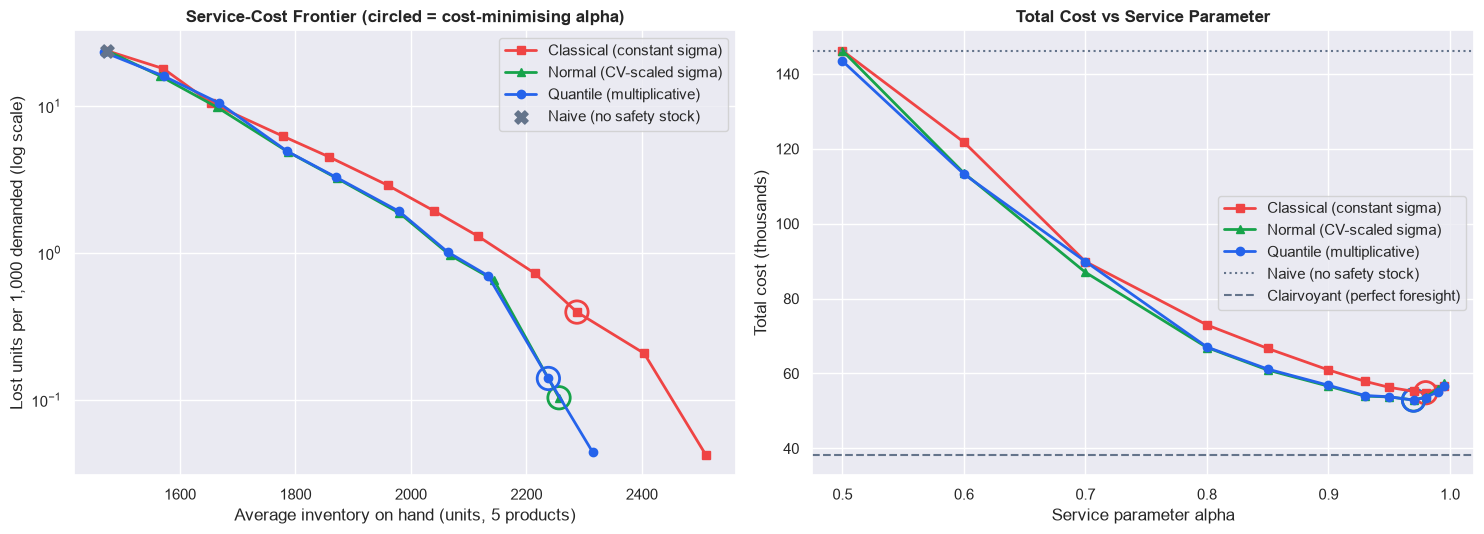

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
styles = {CLASSICAL: (COLORS[CLASSICAL], 's'), CVNORMAL: (COLORS[CVNORMAL], '^'), QUANTILE: (COLORS[QUANTILE], 'o')}

# Left: service-cost frontier (lower-left is better; zero-loss points cannot be shown on a log axis)
ax = axes[0]
for pol, (color, marker) in styles.items():
    full = base_agg[base_agg['policy'] == pol].sort_values('alpha')
    g = full[full['lost'] > 0]
    ax.plot(g['avg_on_hand'], 1000 * g['lost'] / g['demand'], marker=marker, color=color, linewidth=2, label=pol)
    b = full.loc[full['total_cost'].idxmin()]
    if b['lost'] > 0:
        ax.scatter(b['avg_on_hand'], 1000 * b['lost'] / b['demand'], s=260, facecolors='none', edgecolors=color, linewidths=2)
r = base_agg[base_agg['policy'] == NAIVE].iloc[0]
ax.scatter(r['avg_on_hand'], 1000 * r['lost'] / r['demand'], marker='X', s=90, color='#64748b', zorder=3, label=NAIVE)
ax.set_yscale('log')
ax.set_xlabel('Average inventory on hand (units, 5 products)')
ax.set_ylabel('Lost units per 1,000 demanded (log scale)')
ax.set_title('Service-Cost Frontier (circled = cost-minimising alpha)', fontweight='bold')
ax.legend()

# Right: total cost vs alpha
ax = axes[1]
for pol, (color, marker) in styles.items():
    g = base_agg[base_agg['policy'] == pol].sort_values('alpha')
    ax.plot(g['alpha'], g['total_cost'] / 1000, marker=marker, color=color, linewidth=2, label=pol)
    b = g.loc[g['total_cost'].idxmin()]
    ax.scatter(b['alpha'], b['total_cost'] / 1000, s=260, facecolors='none', edgecolors=color, linewidths=2)
for pol, ls in [(NAIVE, ':'), (CLAIRVOYANT, '--')]:
    ax.axhline(base_agg.loc[base_agg['policy'] == pol, 'total_cost'].iloc[0] / 1000, color='#64748b', linestyle=ls, label=pol)
ax.set_xlabel('Service parameter alpha')
ax.set_ylabel('Total cost (thousands)')
ax.set_title('Total Cost vs Service Parameter', fontweight='bold')
ax.legend()

plt.tight_layout()
save_figure(fig, '03_policy_frontier')
plt.show()

In [11]:
# Is the difference consistent on the one real 2024 path? Cost-minimising settings, block by block (5 products x 6 folds = 30 blocks)
def best_alpha(agg, pol):
    g = agg[agg['policy'] == pol]
    return g.loc[g['total_cost'].idxmin(), 'alpha']

def block_costs(blocks, pol, alpha):
    return blocks[(blocks['policy'] == pol) & (blocks['alpha'] == alpha)].set_index(['product', 'fold'])['cost']

best_real = {pol: best_alpha(base_agg, pol) for pol in POLICIES}
print("Cost-minimising alpha on the real path:", best_real)
for ref in (CLASSICAL, CVNORMAL):
    diff = block_costs(base_blocks, ref, best_real[ref]) - block_costs(base_blocks, QUANTILE, best_real[QUANTILE])   # positive = quantile cheaper
    print(f"Quantile vs {ref}: cheaper in {(diff > 0).sum()} of {len(diff)} blocks; mean saving per block {diff.mean():,.0f} "
          f"(std {diff.std():,.0f}, standard error {diff.std() / np.sqrt(len(diff)):,.0f})")

Cost-minimising alpha on the real path: {'Classical (constant sigma)': np.float64(0.98), 'Normal (CV-scaled sigma)': np.float64(0.97), 'Quantile (multiplicative)': np.float64(0.97)}
Quantile vs Classical (constant sigma): cheaper in 18 of 30 blocks; mean saving per block 66 (std 337, standard error 62)
Quantile vs Normal (CV-scaled sigma): cheaper in 28 of 30 blocks; mean saving per block 1 (std 31, standard error 6)


**Observations (one real 2024 demand path)**
- Holding a demand-based safety stock matters far more than how it is calculated. The naive policy (no safety stock) costs about 146k with a 97.6% fill rate, mostly stockout cost (106k); all three safety-stock policies cost 52.9-54.9k at a fill rate close to 100%. Perfect foresight (38k) is the floor, so the price of demand uncertainty is about 15k, mostly extra holding (34.5k against 20.5k).
- The cost-minimising alpha is high (0.97 for the quantile and CV-scaled policies, 0.98 for the constant-sigma one, fill rate about 99.9%) because the unit margin is large relative to the cost of holding a unit. A P90 target would be too low: on this path the quantile policy at alpha 0.90 costs 7.5% more than at 0.97 (56.9k vs 52.9k), and at 0.95 about 1.7% more. The curve is flat between 0.95 and 0.98.
- The quantile policy at 0.97 costs 52.9k against 54.9k for the constant-sigma policy at 0.98 (3.6% lower): stockout cost 0.6k vs 1.8k, holding cost 34.5k vs 35.3k. **But the normal rule whose sigma is proportional to the forecast also costs 52.9k** (52,936), so the gain over the textbook method comes from letting the buffer scale with the forecast level, not from the empirical noise distribution.
- One path cannot separate the policies with confidence: the quantile policy is cheaper than constant sigma in 18 of 30 product-fold blocks, with a mean saving of 66 per block against a standard deviation of 337 (about one standard error). Against the CV-scaled rule the mean saving is 1 per block (28 of 30 blocks are marginally positive, std 31). Stockouts are rare events, so Section 3.1 replays the policies on many simulated paths.


## 3.1 Is the Difference Real? Monte Carlo Over Demand Paths

The 2024 path is a single draw from a noisy process, and stockouts are rare events, so a cost difference of a few percent could be luck. To separate signal from chance we replay the **same reorder points** against many simulated demand paths: each day's demand is the forecast mean times a noise ratio drawn from that fold's training distribution. Differences are paired (same path for every policy) and reported with standard errors.

Two caveats. (i) The noise model is the one the quantile and CV-scaled policies assume, so the test favours them: it shows whether a difference could be chance, not whether the noise model is right (the real path and the calibration table in Section 4 check that). (ii) Only demand changes between paths; the forecasts and reorder points are those of the real 2024 run.


In [12]:
def simulate_paths(n_paths, seed=SEED + 1):
    """Demand paths from the fitted model: each day's forecast mean times a noise ratio drawn from that fold's training distribution."""
    rng = np.random.default_rng(seed)
    out = {p: np.empty((n_paths, T)) for p in PRODUCTS}
    for k in FOLDS:
        lv = ratio_q[ratio_q['fold'] == k].sort_values('level')
        sl = slice((k - 1) * HORIZON, k * HORIZON)
        for p in PRODUCTS:
            noise = np.interp(rng.random((n_paths, HORIZON)), lv['level'].to_numpy(), lv['ratio'].to_numpy())
            out[p][:, sl] = np.rint(MU[p][k][:HORIZON] * noise)
    return out

paths = simulate_paths(N_PATHS)

# The fast simulator must reproduce the full simulator on the real path
e_base = unit_economics(BASE)
st_base = protection_stats(BASE['L'], BASE['R'])
chk_p, chk_a = PRODUCTS[0], 0.97
oc, hc, ls, inv = simulate_cost(ACT[chk_p].tolist(), st_base[chk_p]['quantile'][ALPHAS.index(chk_a)].tolist(), e_base.loc[chk_p, 'Q'],
                                BASE['L'], BASE['R'], e_base.loc[chk_p, 'h_day'], BASE['K'])
ref = base_summary[(base_summary['policy'] == QUANTILE) & (base_summary['alpha'] == chk_a) & (base_summary['product'] == chk_p)].iloc[0]
assert np.allclose([oc, hc, ls, inv], [ref['order_cost'], ref['hold_cost'], ref['lost'], ref['avg_on_hand']])
print("Fast simulator matches the full simulator on the real path.")
sim_demand = np.mean([sum(paths[p][r, WARMUP:].sum() for p in PRODUCTS) for r in range(N_PATHS)])
real_demand = sum(ACT[p][WARMUP:].sum() for p in PRODUCTS)
print(f"Total demand per simulated path {sim_demand:,.0f} vs {real_demand:,.0f} on the real path ({100 * (sim_demand / real_demand - 1):+.1f}%: the mean forecast over-shoots 2024 slightly, see the forecasting notebook)")

Fast simulator matches the full simulator on the real path.
Total demand per simulated path 124,721 vs 121,798 on the real path (+2.4%: the mean forecast over-shoots 2024 slightly, see the forecasting notebook)


In [13]:
def mc_costs(paths, params, policies=POLICIES, q_mult=1.0, n_paths=None, alphas=None):
    """Replay every (policy, alpha, product) against each demand path.
    Returns arrays of shape (path, policy, alpha, product): total cost, average on-hand units and lost units."""
    alphas = ALPHAS if alphas is None else alphas
    e = unit_economics(params)
    st = protection_stats(params['L'], params['R'], alphas)
    n_paths = n_paths or next(iter(paths.values())).shape[0]
    shape = (n_paths, len(policies), len(alphas), len(PRODUCTS))
    out = {k: np.zeros(shape) for k in ('cost', 'inv', 'lost')}
    for ip, p in enumerate(PRODUCTS):
        Q, h, pen = e.loc[p, 'Q'] * q_mult, e.loc[p, 'h_day'], e.loc[p, 'penalty']
        s_lists = {pol: [row.tolist() for row in st[p][KEY[pol]]] for pol in policies}
        for r in range(n_paths):
            actual = paths[p][r].tolist()
            for ipol, pol in enumerate(policies):
                for j, s in enumerate(s_lists[pol]):
                    oc, hc, ls, inv = simulate_cost(actual, s, Q, params['L'], params['R'], h, params['K'])
                    out['cost'][r, ipol, j, ip] = oc + hc + pen * ls
                    out['inv'][r, ipol, j, ip] = inv
                    out['lost'][r, ipol, j, ip] = ls
    return out

def mc_table(mc, paths, policies=POLICIES):
    """Per policy: the alpha with the lowest MEAN cost over the paths, and what that setting delivers."""
    total = mc['cost'].sum(axis=3)                                  # (path, policy, alpha)
    mean = total.mean(axis=0)
    demand = np.mean([sum(paths[p][r, WARMUP:].sum() for p in PRODUCTS) for r in range(total.shape[0])])
    rows = []
    for i, pol in enumerate(policies):
        j = int(mean[i].argmin())
        rows.append({'policy': pol, 'alpha*': ALPHAS[j], 'mean cost': mean[i, j],
                     'std across paths': total[:, i, j].std(ddof=1),
                     'avg inventory (units)': mc['inv'].sum(axis=3).mean(axis=0)[i, j],
                     'fill rate': 1 - mc['lost'].sum(axis=3).mean(axis=0)[i, j] / demand})
    return pd.DataFrame(rows).set_index('policy')

def mc_paired(mc, policies, ref, new):
    """Paired difference cost(ref) - cost(new) over the paths, each at its own mean-cost-minimising alpha. Positive = `new` is cheaper."""
    total = mc['cost'].sum(axis=3)
    mean = total.mean(axis=0)
    ir, inw = policies.index(ref), policies.index(new)
    d = total[:, ir, int(mean[ir].argmin())] - total[:, inw, int(mean[inw].argmin())]
    base = total[:, ir, int(mean[ir].argmin())].mean()
    return {'diff': d.mean(), 'pct': 100 * d.mean() / base, 'se': d.std(ddof=1) / np.sqrt(len(d)),
            'se_pct': 100 * d.std(ddof=1) / np.sqrt(len(d)) / base, 'share_new_cheaper': (d > 0).mean(), 'paths': d}

In [14]:
mc = mc_costs(paths, BASE)
mc_tab = mc_table(mc, paths)
pairs = {f"{r} vs {n}": mc_paired(mc, POLICIES, r, n) for r, n in [(CLASSICAL, QUANTILE), (CVNORMAL, QUANTILE), (CLASSICAL, CVNORMAL)]}
mc_pairs = pd.DataFrame({k: {'mean cost difference': v['diff'], 'as % of first policy': v['pct'], 'standard error': v['se'],
                             'z': v['diff'] / v['se'], 'second policy cheaper in % of paths': 100 * v['share_new_cheaper']}
                         for k, v in pairs.items()}).T
ALPHA_STAR_MC = {pol: mc_tab.loc[pol, 'alpha*'] for pol in POLICIES}
display(mc_tab.round(3))
display(mc_pairs.round(2))
mc_curves = pd.DataFrame(mc['cost'].sum(axis=3).mean(axis=0).T, index=pd.Index(ALPHAS, name='alpha'), columns=POLICIES)
display(mc_curves.round(0))

,alpha*,mean cost,std across paths,avg inventory (units),fill rate
policy,,,,,
Classical (constant sigma),0.99,56576.922,2565.511,2335.111,0.999
Normal (CV-scaled sigma),0.97,54366.681,2252.429,2182.486,0.999
Quantile (multiplicative),0.97,54376.086,2309.077,2166.983,0.999


,mean cost difference,as % of first policy,standard error,z,second policy cheaper in % of paths
Classical (constant sigma) vs Quantile (multiplicative),2200.84,3.89,118.46,18.58,86.00
Normal (CV-scaled sigma) vs Quantile (multiplicative),-9.41,-0.02,43.98,-0.21,49.25
Classical (constant sigma) vs Normal (CV-scaled sigma),2210.24,3.91,116.02,19.05,85.25


,Classical (constant sigma),Normal (CV-scaled sigma),Quantile (multiplicative)
alpha,,,
0.500,192226.0,192226.0,192858.0
0.600,149917.0,148071.0,147921.0
0.700,115984.0,111856.0,111652.0
0.800,89384.0,82934.0,82943.0
0.850,78005.0,71401.0,71631.0
0.900,68096.0,61803.0,62165.0
0.930,62973.0,57397.0,57768.0
0.950,59895.0,55423.0,55620.0
0.970,57566.0,54367.0,54376.0


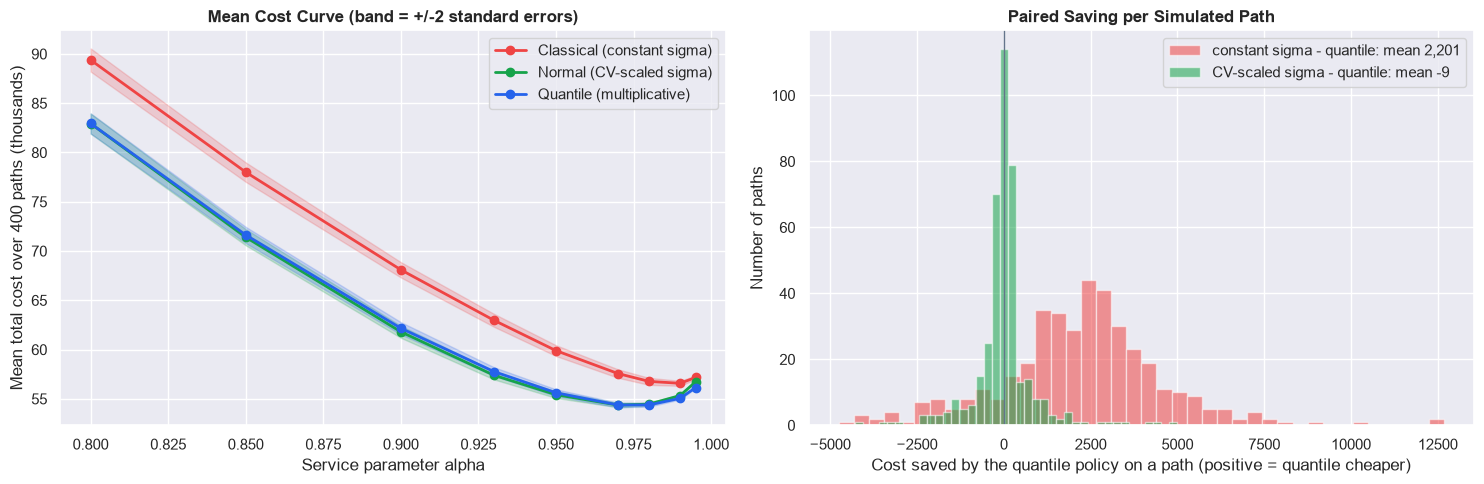

In [15]:
total = mc['cost'].sum(axis=3)
mean_curve, se_curve = total.mean(axis=0), total.std(axis=0, ddof=1) / np.sqrt(total.shape[0])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sel = [j for j, a in enumerate(ALPHAS) if a >= 0.80]
for i, pol in enumerate(POLICIES):
    m, s_ = mean_curve[i, sel] / 1000, 2 * se_curve[i, sel] / 1000
    axes[0].plot([ALPHAS[j] for j in sel], m, marker='o', color=COLORS[pol], linewidth=2, label=pol)
    axes[0].fill_between([ALPHAS[j] for j in sel], m - s_, m + s_, color=COLORS[pol], alpha=0.2)
axes[0].set_xlabel('Service parameter alpha')
axes[0].set_ylabel(f'Mean total cost over {N_PATHS} paths (thousands)')
axes[0].set_title('Mean Cost Curve (band = +/-2 standard errors)', fontweight='bold')
axes[0].legend()

for (label, key), color in zip([('constant sigma - quantile', f"{CLASSICAL} vs {QUANTILE}"), ('CV-scaled sigma - quantile', f"{CVNORMAL} vs {QUANTILE}")],
                               [COLORS[CLASSICAL], COLORS[CVNORMAL]]):
    d = pairs[key]['paths']
    axes[1].hist(d, bins=40, alpha=0.55, color=color, label=f"{label}: mean {d.mean():,.0f}")
axes[1].axvline(0, color='#64748b', linewidth=1)
axes[1].set_xlabel('Cost saved by the quantile policy on a path (positive = quantile cheaper)')
axes[1].set_ylabel('Number of paths')
axes[1].set_title('Paired Saving per Simulated Path', fontweight='bold')
axes[1].legend()
plt.tight_layout()
save_figure(fig, '03_monte_carlo')
plt.show()

**Observations**
- Over 400 simulated paths the quantile policy is **3.9% cheaper than the constant-sigma policy** (mean saving 2,200 per path, standard error 118, z of about 19; cheaper on 86% of paths). The difference seen on the real path (3.6%) is therefore not luck, at least under this noise model.
- It is **not** cheaper than the CV-scaled normal rule: the difference is -9 per path (-0.02%, standard error 44), each policy wins on about half of the paths, both choose alpha 0.97 and hold the same inventory (about 2,170-2,180 units). The advantage over the textbook method is explained by **heteroscedasticity**, a buffer that grows with the forecast, not by the empirical quantile distribution. Over an 8-day interval the sum of independent daily errors is close to normal, so a normal with the right spread is enough.
- The constant-sigma rule needs a higher alpha (0.99) to compensate for under-protecting in peak periods, and ends up holding about 8% more inventory (2,335 vs 2,167 units).
- The simulated paths contain 2.4% more demand than the real 2024 (the mean forecast over-shoots slightly), which is why mean costs here (about 54.4k) are above the real-path costs (52.9k); the comparison between policies is unaffected because every policy sees the same paths.


## 3.2 Choosing Alpha Without Peeking

Above, alpha is chosen on the same demand it is then scored on, which is slightly optimistic. Two checks:

- **Nested choice**: pick alpha on folds 1-3 and score it on folds 4-6, and the other way round. If the best alpha changes between seasons, a fixed alpha is fragile.
- **Critical-ratio rule**: the textbook starting point alpha ≈ 1 − (annual holding cost per unit × order quantity) / (stock-out cost per unit × annual demand), which needs no simulation.


In [16]:
def nested_alpha(blocks, pol):
    """Choose alpha on folds 1-3 and score it on folds 4-6, and vice versa."""
    b = blocks[blocks['policy'] == pol].groupby(['alpha', 'fold'])['cost'].sum().unstack('fold')
    first, second = [1, 2, 3], [4, 5, 6]
    a1, a2 = b[first].sum(axis=1).idxmin(), b[second].sum(axis=1).idxmin()
    return {'policy': pol, 'alpha chosen on folds 1-3': a1, 'alpha chosen on folds 4-6': a2,
            'cost, alpha chosen in-sample': b.sum(axis=1).min(),
            'cost, alpha chosen out-of-sample': b.loc[a1, second].sum() + b.loc[a2, first].sum()}

nested = pd.DataFrame([nested_alpha(base_blocks, pol) for pol in POLICIES]).set_index('policy')
nested['optimism of in-sample choice (%)'] = 100 * (nested['cost, alpha chosen out-of-sample'] / nested['cost, alpha chosen in-sample'] - 1)
display(nested.round(2))

# Critical-ratio rule of thumb: alpha ~ 1 - (annual holding cost per unit x Q) / (stock-out cost per unit x annual demand)
e_cr = unit_economics(BASE)
crit = pd.DataFrame({'critical-ratio alpha': 1 - e_cr['h_day'] * 365 * e_cr['Q'] / (e_cr['penalty'] * e_cr['annual_demand']),
                     'EOQ (units)': e_cr['Q'], 'stock-out cost per unit': e_cr['penalty']})
crit.round(3)

,alpha chosen on folds 1-3,alpha chosen on folds 4-6,"cost, alpha chosen in-sample","cost, alpha chosen out-of-sample",optimism of in-sample choice (%)
policy,,,,,
Classical (constant sigma),1.00,0.90,54860.30,65561.45,19.51
Normal (CV-scaled sigma),0.97,0.97,52935.97,52935.97,0.00
Quantile (multiplicative),0.97,0.97,52892.39,52892.39,0.00


,critical-ratio alpha,EOQ (units),stock-out cost per unit
product_id,,,
A,0.991,492.0,37.748
B,0.991,481.0,36.461
C,0.991,487.0,35.633
D,0.991,493.0,37.276
E,0.991,486.0,36.426


**Observations**
- The quantile and CV-scaled policies pick alpha 0.97 in **both** halves of the year, so choosing alpha out of sample costs nothing (0% optimism). The constant-sigma policy picks 0.995 on folds 1-3 and 0.90 on folds 4-6, and applying each half's choice to the other half costs 65.6k against 54.9k (+19.5%). A constant-sigma buffer is too small in peaks and too large in troughs, so there is no single right alpha for it. This is a second argument, beyond mean cost, for a buffer that scales with the forecast.
- The critical-ratio rule gives alpha ≈ 0.99 for every product (EOQ 481-493 units, stock-out cost 36-38 per unit). That is close to the simulated optimum (0.97-0.98) and a sensible starting point without simulation; it is slightly high because it ignores the review period and the overshoot of orders. The cost curve is flat there (Monte Carlo: 54.4k at 0.97-0.98 against 55.1k at 0.99, +1.2%).


## 4. Where Do the Two Policies Differ?

Two checks. **(a) Calibration of the interval demand**: does the reorder point set for a target probability of 90% really cover about 90% of actual protection-interval demand, in every period? **(b) Matched service**: at the same overall fill rate (about 99.5%, close to the range where policies operate economically), how much inventory does each policy hold, and where do the remaining lost sales occur?

In [17]:
n_int = BASE['L'] + BASE['R']
st_base = protection_stats(BASE['L'], BASE['R'])
a90 = ALPHAS.index(0.90)
day_idx = np.arange(T)
inside = (day_idx % HORIZON) + n_int <= HORIZON          # windows that lie fully inside one fold

def interval_coverage_rate(key, mask):
    hits = [(window_sums(ACT[p], n_int) <= st_base[p][key][a90])[mask] for p in PRODUCTS]
    return np.concatenate(hits).mean()

fold_start = fc.groupby('fold')['date'].min()
rows = []
for k in FOLDS:
    mask = inside & (day_idx // HORIZON == k - 1)
    rows.append({'fold': f"{k} ({fold_start[k]:%b})", **{pol: interval_coverage_rate(KEY[pol], mask) for pol in POLICIES}})
rows.append({'fold': 'All', **{pol: interval_coverage_rate(KEY[pol], inside) for pol in POLICIES}})
interval_cov = pd.DataFrame(rows).set_index('fold')
(interval_cov * 100).round(1)

,Classical (constant sigma),Normal (CV-scaled sigma),Quantile (multiplicative)
fold,,,
1 (Jan),95.1,97.7,97.4
2 (Mar),81.9,89.1,89.1
3 (May),94.3,94.7,94.7
4 (Jul),92.5,88.7,88.3
5 (Sep),98.9,95.1,95.1
6 (Nov),94.7,93.2,93.2
All,92.9,93.1,93.0


In [18]:
TARGET_FILL = 0.995
ev = np.arange(T) >= WARMUP
situations = {
    'Promotion days': lambda p: PROMO[p] == 1,
    'No-promotion days': lambda p: PROMO[p] == 0,
    'Peak months (Mar-May)': lambda p: np.isin(MONTH, [3, 4, 5]),
    'Trough months (Aug-Oct)': lambda p: np.isin(MONTH, [8, 9, 10]),
}
matched, rows = {}, []
for pol in POLICIES:
    g = base_agg[base_agg['policy'] == pol]
    matched[pol] = g.iloc[(g['fill_rate'] - TARGET_FILL).abs().argmin()]
    row = {'policy': pol, 'alpha': matched[pol]['alpha'], 'overall fill rate': matched[pol]['fill_rate'],
           'avg inventory (units)': matched[pol]['avg_on_hand'], 'holding cost': matched[pol]['hold_cost']}
    for name, mask_fn in situations.items():
        lost = sum(base_daily[(pol, matched[pol]['alpha'], p)]['lost'][ev & mask_fn(p)].sum() for p in PRODUCTS)
        demand = sum(ACT[p][ev & mask_fn(p)].sum() for p in PRODUCTS)
        row[f'lost per 1,000: {name}'] = 1000 * lost / demand
    rows.append(row)
matched_table = pd.DataFrame(rows).set_index('policy')
matched_table.round(3)

,alpha,overall fill rate,avg inventory (units),holding cost,"lost per 1,000: Promotion days","lost per 1,000: No-promotion days","lost per 1,000: Peak months (Mar-May)","lost per 1,000: Trough months (Aug-Oct)"
policy,,,,,,,,
Classical (constant sigma),0.85,0.995,1857.251,28633.033,0.187,6.070,10.054,0.874
Normal (CV-scaled sigma),0.80,0.995,1786.669,27546.888,2.525,5.721,10.041,0.570
Quantile (multiplicative),0.80,0.995,1785.882,27534.755,2.463,5.786,10.233,0.532


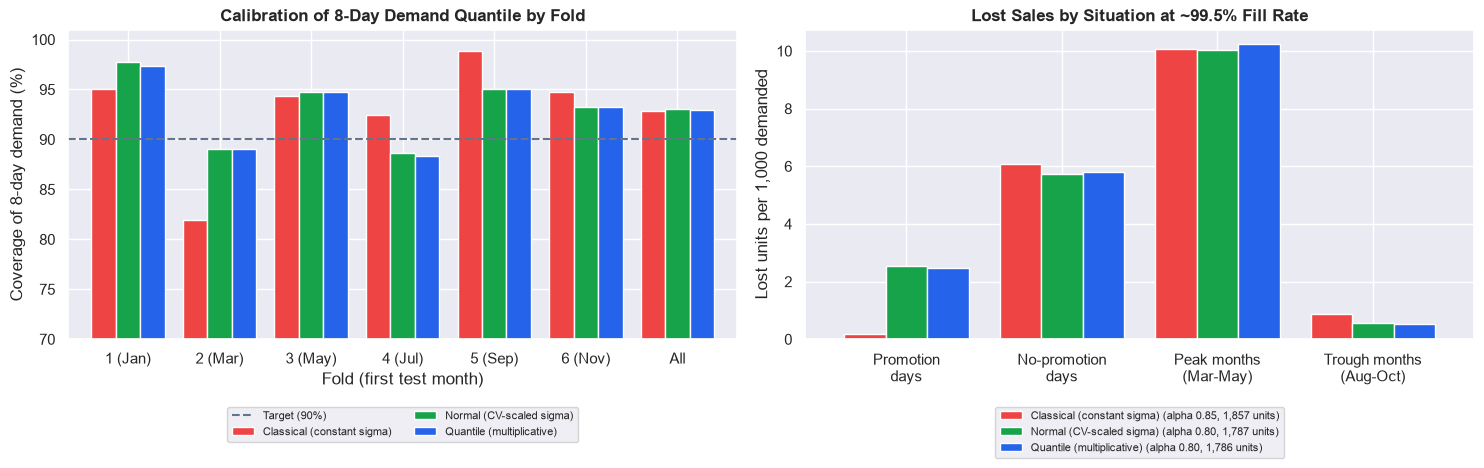

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = [COLORS[p] for p in POLICIES]

(interval_cov * 100).plot(kind='bar', ax=axes[0], width=0.8, color=colors)
axes[0].axhline(90, color='#64748b', linestyle='--', linewidth=1.5, label='Target (90%)')
axes[0].set_ylim(70, 101)
axes[0].set_ylabel('Coverage of 8-day demand (%)')
axes[0].set_xlabel('Fold (first test month)')
axes[0].set_title('Calibration of 8-Day Demand Quantile by Fold', fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

lost_cols = [c for c in matched_table.columns if c.startswith('lost per 1,000')]
lost_plot = matched_table[lost_cols].rename(columns=lambda c: c.replace('lost per 1,000: ', '')).T
lost_plot = lost_plot.rename(index={'Promotion days': 'Promotion\ndays', 'No-promotion days': 'No-promotion\ndays',
                                    'Peak months (Mar-May)': 'Peak months\n(Mar-May)', 'Trough months (Aug-Oct)': 'Trough months\n(Aug-Oct)'})
lost_plot.columns = [f"{pol} (alpha {matched[pol]['alpha']:.2f}, {matched[pol]['avg_on_hand']:,.0f} units)" for pol in lost_plot.columns]
lost_plot.plot(kind='bar', ax=axes[1], width=0.8, color=colors)
axes[1].set_ylabel('Lost units per 1,000 demanded')
axes[1].set_title('Lost Sales by Situation at ~99.5% Fill Rate', fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)

plt.tight_layout()
save_figure(fig, '03_policy_diagnostics')
plt.show()

**Observations**
- **Calibration.** The P90 reorder point covers 89% of 8-day demand in the March fold (peak season) for both the quantile and the CV-scaled rules, against 82% for constant sigma, which over-protects in September (98.9% against 95.1%). The picture is not one-sided: in July the level-proportional rules fall below target (88.3-88.7%) where constant sigma reaches 92.5%. The spread across folds is about 9 percentage points for the level-proportional rules (88.3-97.7%) and 17 for constant sigma (81.9-98.9%). Overall all three cover about 93% (conservative, since the noise distribution is estimated in-sample). The quantile and CV-scaled rules are almost indistinguishable here as well.
- At the same fill rate of about 99.5%, the quantile and CV-scaled policies hold about 4% less inventory than constant sigma (1,786 vs 1,857 units; holding cost 27.5k vs 28.6k).
- The remaining lost sales are concentrated in March-May (about 10 per 1,000 demanded for every policy, against 0.5-0.9 in the trough months). The total is only about 600 units out of about 122,000 demanded, so differences by situation rest on very few events and should not be over-read; for example promotion days show 0.2 lost per 1,000 for constant sigma against 2.5 for the other two policies, while non-promotion days show 5.7-6.1. A season-specific alpha is a possible refinement that has not been tested here.


## 5. Sensitivity to the Assumptions

Each scenario changes one assumption from the base case and re-optimises α for each policy. The question is whether the conclusions survive, not what the absolute costs are. Costs on the real 2024 path are shown for reference; the **saving of the quantile policy is measured by Monte Carlo** (100 simulated paths per scenario, paired differences) so that it comes with a standard error.

In [20]:
SCENARIOS = {
    'Base (L=7, R=1)': {},
    'Lead time 3 days': {'L': 3},
    'Lead time 14 days': {'L': 14},
    'Weekly review (R=7)': {'R': 7},
    'High holding cost (35% per year)': {'holding_rate': 0.35},
    'Low margin (cost = 80% of price)': {'cost_ratio': 0.80},
    'High stockout penalty (goodwill 2x margin)': {'goodwill': 2.0},
    'High ordering cost (K=300)': {'K': 300.0},
}

rows = []
for name, change in SCENARIOS.items():
    params = {**BASE, **change}
    if change:
        s_, b_, _ = evaluate(params)
        a_ = aggregate(s_)
    else:
        s_, b_, a_ = base_summary, base_blocks, base_agg
    row = {'scenario': name}
    for pol in (NAIVE,) + POLICIES + (CLAIRVOYANT,):
        g = a_[a_['policy'] == pol]
        row[f'{pol} cost'] = g.loc[g['total_cost'].idxmin(), 'total_cost']
        if pol in POLICIES:
            row[f'{pol} alpha'] = g.loc[g['total_cost'].idxmin(), 'alpha']
    mc_s = mc_costs(paths, params, n_paths=SENS_PATHS)
    for ref, tag in ((CLASSICAL, 'constant sigma'), (CVNORMAL, 'CV-scaled sigma')):
        pr = mc_paired(mc_s, POLICIES, ref, QUANTILE)
        row[f'MC saving vs {tag} (%)'] = pr['pct']
        row[f'MC saving vs {tag}, SE (%)'] = pr['se_pct']
    rows.append(row)

sensitivity = pd.DataFrame(rows).set_index('scenario')
show = sensitivity[[f'{NAIVE} cost'] + [f'{p} cost' for p in POLICIES] + [f'{CLAIRVOYANT} cost'] + [f'{p} alpha' for p in POLICIES] +
                   ['MC saving vs constant sigma (%)', 'MC saving vs constant sigma, SE (%)',
                    'MC saving vs CV-scaled sigma (%)', 'MC saving vs CV-scaled sigma, SE (%)']]
show.round(2)

,Naive (no safety stock) cost,Classical (constant sigma) cost,Normal (CV-scaled sigma) cost,Quantile (multiplicative) cost,Clairvoyant (perfect foresight) cost,Classical (constant sigma) alpha,Normal (CV-scaled sigma) alpha,Quantile (multiplicative) alpha,MC saving vs constant sigma (%),"MC saving vs constant sigma, SE (%)",MC saving vs CV-scaled sigma (%),"MC saving vs CV-scaled sigma, SE (%)"
scenario,,,,,,,,,,,,
"Base (L=7, R=1)",146191.18,54860.30,52935.97,52892.39,38225.22,0.98,0.97,0.97,4.03,0.40,-0.05,0.19
Lead time 3 days,122307.24,49571.68,48443.03,47824.65,38649.27,0.97,0.93,0.90,2.79,0.37,0.05,0.10
Lead time 14 days,159967.35,58259.45,55753.50,55971.58,37872.10,0.95,0.93,0.93,4.83,0.47,0.05,0.18
Weekly review (R=7),76655.57,69599.27,69028.50,69530.15,59183.93,0.70,0.70,0.80,-0.28,0.24,-0.07,0.05
High holding cost (35% per year),182130.16,65932.90,62715.59,62609.39,45447.19,0.97,0.93,0.93,4.54,0.46,-0.13,0.13
Low margin (cost = 80% of price),111158.84,58126.45,60289.41,59958.29,42630.20,0.93,0.93,0.95,3.20,0.38,-0.04,0.11
High stockout penalty (goodwill 2x margin),358420.95,57107.90,53720.78,53963.27,38225.22,1.00,0.98,0.98,5.69,0.83,-0.36,0.31
High ordering cost (K=300),148107.46,90609.70,85592.38,87431.42,74360.80,0.95,0.90,0.93,1.62,0.28,-0.03,0.09


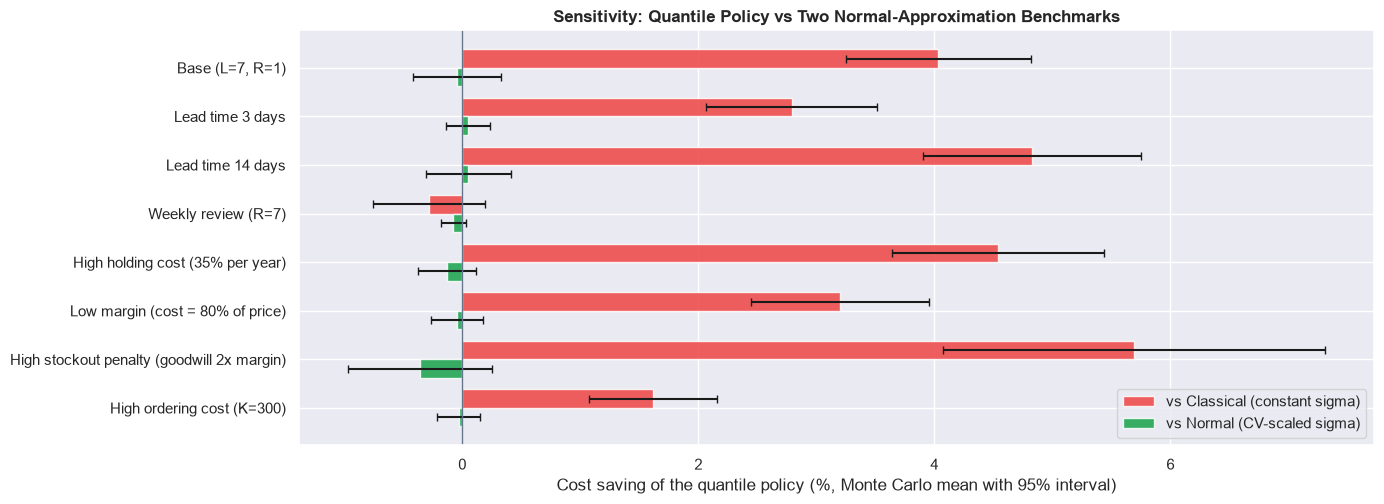

In [21]:
fig, ax = plt.subplots(figsize=(14, 5.2))
sens = sensitivity.iloc[::-1]
y, h = np.arange(len(sens)), 0.38
ax.barh(y + h / 2, sens['MC saving vs constant sigma (%)'], h, xerr=1.96 * sens['MC saving vs constant sigma, SE (%)'],
        color=COLORS[CLASSICAL], alpha=0.85, label='vs Classical (constant sigma)', capsize=3)
ax.barh(y - h / 2, sens['MC saving vs CV-scaled sigma (%)'], h, xerr=1.96 * sens['MC saving vs CV-scaled sigma, SE (%)'],
        color=COLORS[CVNORMAL], alpha=0.85, label='vs Normal (CV-scaled sigma)', capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(sens.index)
ax.axvline(0, color='#64748b', linewidth=1)
ax.set_xlabel('Cost saving of the quantile policy (%, Monte Carlo mean with 95% interval)')
ax.set_title('Sensitivity: Quantile Policy vs Two Normal-Approximation Benchmarks', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
save_figure(fig, '03_sensitivity')
plt.show()

**Observations**
- Safety stock matters in every scenario: the naive policy costs 1.7 to 6.6 times as much as the quantile policy, except under weekly review (1.1x), where the fixed review cycle and order quantities dominate the cost.
- **Against the constant-sigma policy** the quantile policy is cheaper in seven of eight scenarios, by 1.6-5.7% (Monte Carlo, each at least 5 standard errors from zero): base case 4.0%, lead time 3 and 14 days 2.8% and 4.8%, high holding cost 4.5%, low margin 3.2%, high stockout penalty 5.7%, high ordering cost 1.6%. Under weekly review the two are level (-0.3%, standard error 0.2%). The single real path had suggested the quantile policy was 3.2% *more* expensive in the low-margin scenario; the Monte Carlo shows that was one path's luck.
- **Against the CV-scaled normal rule** the difference stays within +/-0.4% in every scenario and is never clearly different from zero (largest: -0.36%, standard error 0.31%). The two rules are interchangeable.
- The cost-minimising alpha of the quantile policy ranges from 0.80 (weekly review) to 0.98 (high stockout penalty), so a fixed P90 or P95 target should be treated as an output of the cost trade-off, not an input.


## 6. Beyond a Single Service Parameter

So far the only decision variable was one service parameter alpha, shared by all products, with the order quantity fixed at the EOQ. Two questions remain.

**6.1 Is the EOQ still right once a safety stock is used?** The EOQ ignores the interaction between order size and the reorder point, so we search jointly over the order quantity (as a multiple of the EOQ) and alpha, by simulation (Monte Carlo mean cost over the demand paths).


Best cell: Q = 1.0 x EOQ, alpha = 0.97: cost 54,283; best with Q = EOQ: 54,283 (+0.0%)


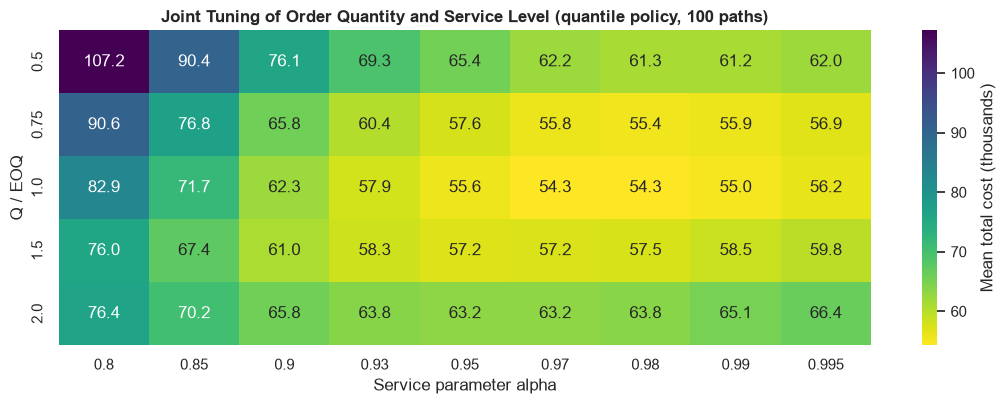

In [22]:
Q_MULTS = (0.5, 0.75, 1.0, 1.5, 2.0)
grid = {}
for m in Q_MULTS:
    r = mc_costs(paths, BASE, policies=(QUANTILE,), q_mult=m, n_paths=GRID_PATHS)
    grid[m] = r['cost'].sum(axis=3).mean(axis=0)[0]                  # mean total cost per alpha
grid_df = pd.DataFrame(grid, index=ALPHAS).T
grid_df.index.name = 'Q / EOQ'
best_q, best_a = grid_df.stack().idxmin()
eoq_best = grid_df.loc[1.0].min()
print(f"Best cell: Q = {best_q} x EOQ, alpha = {best_a}: cost {grid_df.stack().min():,.0f}; "
      f"best with Q = EOQ: {eoq_best:,.0f} ({100 * (eoq_best / grid_df.stack().min() - 1):+.1f}%)")

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(grid_df.loc[:, grid_df.columns >= 0.80] / 1000, annot=True, fmt='.1f', cmap='viridis_r', cbar_kws={'label': 'Mean total cost (thousands)'}, ax=ax)
ax.set_xlabel('Service parameter alpha')
ax.set_title(f'Joint Tuning of Order Quantity and Service Level (quantile policy, {GRID_PATHS} paths)', fontweight='bold')
plt.tight_layout()
save_figure(fig, '03_alpha_q_grid')
plt.show()

**Observations**
- The best cell of the grid is Q = 1.0 x EOQ with alpha 0.97 (cost 54.3k): the EOQ is already the best of the tested order quantities. Q = 0.75 x EOQ costs 2.1% more (55.4k, best alpha 0.98), Q = 1.5 x EOQ 5.3% more (57.2k, best alpha 0.95), and the extremes 0.5x and 2x cost 13% and 16% more.
- The best alpha falls as Q grows (0.95 at 1.5x and 2x) because larger orders already provide cycle stock. The grid is coarse (five multiples), and K was set so that the EOQ is about one week of demand, so this confirms the base case rather than proving the EOQ optimal in general.


**6.2 How should a limited inventory budget be shared across products?** With a budget (or a service target) the products are no longer independent, and the best alpha may differ per product. This is a multiple-choice allocation problem that we solve as a binary MILP (`scipy.optimize.milp`, HiGHS). Let x<sub>pj</sub> = 1 if product *p* uses service level α<sub>j</sub>, and use Monte Carlo averages for the expected total cost c<sub>pj</sub>, the expected inventory value v<sub>pj</sub> (average on-hand units x unit cost) and the expected lost units ℓ<sub>pj</sub>:

- **(A) Budget**: minimise Σ c<sub>pj</sub> x<sub>pj</sub> subject to Σ<sub>j</sub> x<sub>pj</sub> = 1 for every product and Σ v<sub>pj</sub> x<sub>pj</sub> ≤ B.
- **(B) Service level**: minimise Σ v<sub>pj</sub> x<sub>pj</sub> subject to Σ<sub>j</sub> x<sub>pj</sub> = 1 and Σ ℓ<sub>pj</sub> x<sub>pj</sub> ≤ (1 − f) Σ<sub>p</sub> D<sub>p</sub>, with f the target fill rate.

The reference is the policy a planner would use without the model: **one common alpha** for all products (the best feasible one). A fine alpha grid (steps of 0.005) is used so that a common alpha is not penalised by coarse steps. Two cases: the base case (identical cost structure) and an **illustration with different margins** (unit cost 45-85% of price, hypothetical because the data has no costs) to show what the model does when products really differ. Allocations are chosen on Monte Carlo means and then checked on the real 2024 path.


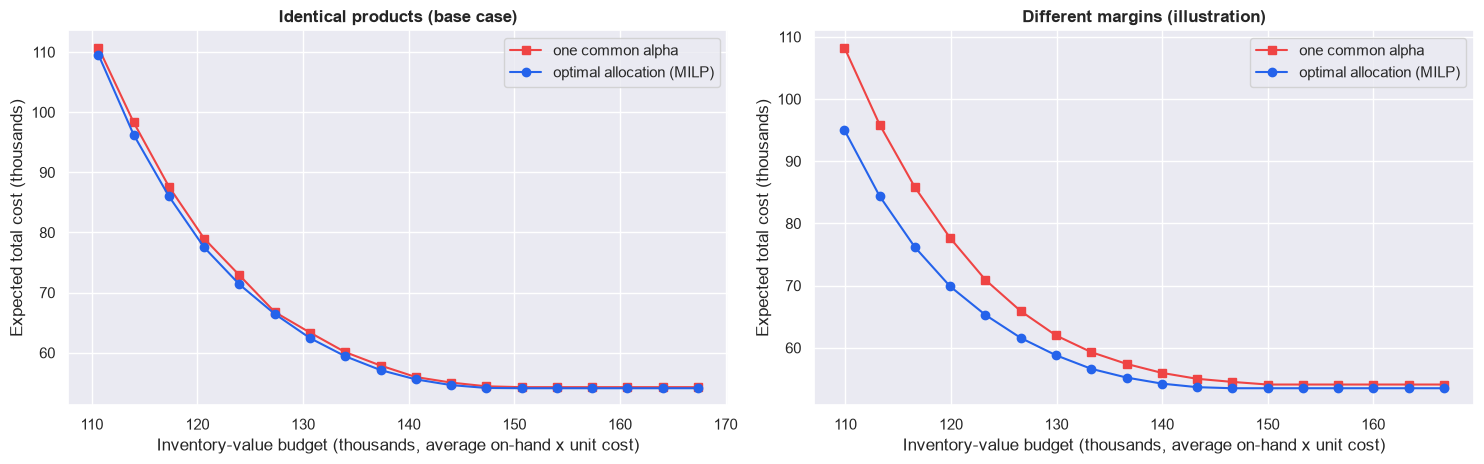

Gain of the optimal allocation over one common alpha: identical products up to 2.10%, different margins up to 12.25%


In [23]:
def mc_tables(mc, params, i_pol):
    """Expected cost, inventory value and lost units per (product, alpha) from the Monte Carlo runs."""
    e = unit_economics(params)
    cost = mc['cost'][:, i_pol].mean(axis=0).T
    inv_val = (mc['inv'][:, i_pol].mean(axis=0) * e['cost'].to_numpy()).T
    lost = mc['lost'][:, i_pol].mean(axis=0).T
    return cost, inv_val, lost

def allocate(cost, inv_val, lost, budget=None, max_lost=None, minimise='cost'):
    """Pick one alpha per product (binary MILP). Returns the chosen alpha index per product, or None if infeasible."""
    P, J = cost.shape
    c = (cost if minimise == 'cost' else inv_val).ravel()
    cons = [LinearConstraint(np.kron(np.eye(P), np.ones((1, J))), 1, 1)]          # exactly one alpha per product
    if budget is not None:
        cons.append(LinearConstraint(inv_val.reshape(1, -1), -np.inf, budget))     # inventory-value budget
    if max_lost is not None:
        cons.append(LinearConstraint(lost.reshape(1, -1), -np.inf, max_lost))      # service level
    res = milp(c, constraints=cons, integrality=np.ones(P * J), bounds=Bounds(0, 1))
    return res.x.reshape(P, J).argmax(axis=1) if res.success else None

def uniform_alpha(cost, inv_val, lost, budget=None, max_lost=None, minimise='cost'):
    """Same alpha for every product: the best feasible one (the policy a planner would use without the model)."""
    P, J = cost.shape
    best = None
    for j in range(J):
        if budget is not None and inv_val[:, j].sum() > budget: continue
        if max_lost is not None and lost[:, j].sum() > max_lost: continue
        v = (cost if minimise == 'cost' else inv_val)[:, j].sum()
        if best is None or v < best[0]:
            best = (v, j)
    return None if best is None else np.full(P, best[1])

def total_of(table, idx):
    return table[np.arange(len(idx)), idx].sum()

def frontier(cost, inv_val, lost, n=18):
    """Cost versus inventory-value budget: optimal allocation (MILP) against one common alpha."""
    tot = inv_val.sum(axis=0)
    rows = []
    for b in np.linspace(tot[AF.index(0.70)], tot.max(), n):
        a_m, a_u = allocate(cost, inv_val, lost, budget=b), uniform_alpha(cost, inv_val, lost, budget=b)
        rows.append({'budget': b, 'MILP': total_of(cost, a_m), 'one common alpha': total_of(cost, a_u)})
    f = pd.DataFrame(rows)
    f['gain (%)'] = 100 * (1 - f['MILP'] / f['one common alpha'])
    return f

# --- base case: identical products (a fine alpha grid, so that a common alpha is not penalised by coarse steps)
mc_fine = mc_costs(paths, BASE, policies=(QUANTILE,), n_paths=GRID_PATHS, alphas=AF)
cost_b, inv_b, lost_b = mc_tables(mc_fine, BASE, 0)
fr_base = frontier(cost_b, inv_b, lost_b)

# --- illustration: products with different margins (hypothetical unit costs; the data has none)
HET = {**BASE, 'cost_ratio': pd.Series({'A': 0.45, 'B': 0.55, 'C': 0.65, 'D': 0.75, 'E': 0.85})}
mc_het = mc_costs(paths, HET, policies=(QUANTILE,), n_paths=GRID_PATHS, alphas=AF)
cost_h, inv_h, lost_h = mc_tables(mc_het, HET, 0)
fr_het = frontier(cost_h, inv_h, lost_h)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)
for ax, fr, title in zip(axes, (fr_base, fr_het), ('Identical products (base case)', 'Different margins (illustration)')):
    ax.plot(fr['budget'] / 1000, fr['one common alpha'] / 1000, marker='s', color=COLORS[CLASSICAL], label='one common alpha')
    ax.plot(fr['budget'] / 1000, fr['MILP'] / 1000, marker='o', color=COLORS[QUANTILE], label='optimal allocation (MILP)')
    ax.set_xlabel('Inventory-value budget (thousands, average on-hand x unit cost)')
    ax.set_ylabel('Expected total cost (thousands)')
    ax.set_title(title, fontweight='bold')
    ax.legend()
plt.tight_layout()
save_figure(fig, '03_budget_frontier')
plt.show()
print(f"Gain of the optimal allocation over one common alpha: identical products up to {fr_base['gain (%)'].max():.2f}%, "
      f"different margins up to {fr_het['gain (%)'].max():.2f}%")

In [24]:
# A concrete budget: 90% of the inventory value that the unconstrained cost-minimising allocation would hold
def concrete(cost, inv_val, lost, params, mc_arr, i_pol, share=0.90):
    free = allocate(cost, inv_val, lost)
    budget = share * total_of(inv_val, free)
    a_m, a_u = allocate(cost, inv_val, lost, budget=budget), uniform_alpha(cost, inv_val, lost, budget=budget)
    return budget, a_m, a_u

def real_path(alpha_idx, params):
    e, st = unit_economics(params), protection_stats(params['L'], params['R'], AF)
    cost = value = lost = demand = 0.0
    for ip, p in enumerate(PRODUCTS):
        oc, hc, ls, inv = simulate_cost(ACT[p].tolist(), st[p]['quantile'][alpha_idx[ip]].tolist(), e.loc[p, 'Q'], params['L'], params['R'],
                                        e.loc[p, 'h_day'], params['K'])
        cost += oc + hc + e.loc[p, 'penalty'] * ls
        value += inv * e.loc[p, 'cost']
        lost += ls
        demand += ACT[p][WARMUP:].sum()
    return cost, value, 1 - lost / demand

rows = []
for label, (cost_x, inv_x, lost_x, params_x) in {'Identical products': (cost_b, inv_b, lost_b, BASE),
                                                  'Different margins (illustration)': (cost_h, inv_h, lost_h, HET)}.items():
    budget, a_m, a_u = concrete(cost_x, inv_x, lost_x, params_x, None, None)
    for name, idx in (('one common alpha', a_u), ('optimal allocation', a_m)):
        c_rp, v_rp, f_rp = real_path(idx, params_x)
        rows.append({'case': label, 'allocation': name, 'budget': budget, 'alpha per product (A-E)': ' / '.join(f'{AF[j]:g}' for j in idx),
                     'expected cost (MC)': total_of(cost_x, idx), 'expected inventory value (MC)': total_of(inv_x, idx),
                     'cost on the real 2024 path': c_rp, 'inventory value on the real path': v_rp, 'fill rate on the real path': f_rp})
allocation = pd.DataFrame(rows).set_index(['case', 'allocation'])
display(allocation.round(3))

# Service-level formulation: least inventory value subject to a fill-rate target
TARGET = 0.995
demand_mc = np.mean([sum(paths[p][r, WARMUP:].sum() for p in PRODUCTS) for r in range(GRID_PATHS)])
rows = []
for label, (cost_x, inv_x, lost_x) in {'Identical products': (cost_b, inv_b, lost_b), 'Different margins (illustration)': (cost_h, inv_h, lost_h)}.items():
    for name, idx in (('one common alpha', uniform_alpha(cost_x, inv_x, lost_x, max_lost=(1 - TARGET) * demand_mc, minimise='inventory')),
                      ('optimal allocation', allocate(cost_x, inv_x, lost_x, max_lost=(1 - TARGET) * demand_mc, minimise='inventory'))):
        rows.append({'case': label, 'allocation': name, 'alpha per product (A-E)': ' / '.join(f'{AF[j]:g}' for j in idx),
                     'expected inventory value': total_of(inv_x, idx), 'expected cost': total_of(cost_x, idx),
                     'expected fill rate': 1 - total_of(lost_x, idx) / demand_mc})
service_alloc = pd.DataFrame(rows).set_index(['case', 'allocation'])
display(service_alloc.round(4))

budget  \
case                             allocation                       
Identical products               one common alpha    134560.103   
                                 optimal allocation  134560.103   
Different margins (illustration) one common alpha    131935.618   
                                 optimal allocation  131935.618   

                                                                   alpha per product (A-E)  \
case                             allocation                                                  
Identical products               one common alpha         0.92 / 0.92 / 0.92 / 0.92 / 0.92   
                                 optimal allocation   0.915 / 0.935 / 0.935 / 0.905 / 0.91   
Different margins (illustration) one common alpha    0.905 / 0.905 / 0.905 / 0.905 / 0.905   
                                 optimal allocation  0.955 / 0.955 / 0.935 / 0.875 / 0.825   

                                                     expected cost (MC)  \
case                             allocation                               
Identical products               one common alpha             59360.560   
                                 optimal allocation           58956.728   
Different margins (illustration) one common alpha             60722.580   
                                 optimal allocation           57394.247   

                                                     expected inventory value (MC)  \
case                             allocation                                          
Identical products               one common alpha                       134484.411   
                                 optimal allocation                     134486.029   
Different margins (illustration) one common alpha                       131284.733   
                                 optimal allocation                     131930.262   

                                                     cost on the real 2024 path  \
case                             allocation                                       
Identical products               one common alpha                     54900.448   
                                 optimal allocation                   54306.114   
Different margins (illustration) one common alpha                     55777.341   
                                 optimal allocation                   53457.808   

                                                     inventory value on the real path  \
case                             allocation                                             
Identical products               one common alpha                          138728.150   
                                 optimal allocation                        138562.960   
Different margins (illustration) one common alpha                          135988.232   
                                 optimal allocation                        136581.527   

                                                     fill rate on the real path  
case                             allocation                                      
Identical products               one common alpha                         0.999  
                                 optimal allocation                       0.999  
Different margins (illustration) one common alpha                         0.999  
                                 optimal allocation                       0.999

alpha per product (A-E)  \
case                             allocation                                                  
Identical products               one common alpha    0.865 / 0.865 / 0.865 / 0.865 / 0.865   
                                 optimal allocation     0.865 / 0.875 / 0.87 / 0.84 / 0.85   
Different margins (illustration) one common alpha         0.86 / 0.86 / 0.86 / 0.86 / 0.86   
                                 optimal allocation    0.875 / 0.88 / 0.86 / 0.845 / 0.825   

                                                     expected inventory value  \
case                             allocation                                     
Identical products               one common alpha                 125973.3351   
                                 optimal allocation               125364.6059   
Different margins (illustration) one common alpha                 124688.3351   
                                 optimal allocation               123917.0124   

                                                     expected cost  \
case                             allocation                          
Identical products               one common alpha       68530.8914   
                                 optimal allocation     69228.0493   
Different margins (illustration) one common alpha       68106.0513   
                                 optimal allocation     66546.1494   

                                                     expected fill rate  
case                             allocation                              
Identical products               one common alpha                0.9952  
                                 optimal allocation              0.9950  
Different margins (illustration) one common alpha                0.9951  
                                 optimal allocation              0.9950

**Observations**
- **Budget (A).** With nearly identical products the optimal allocation barely beats one common alpha: 0.7% lower expected cost at a budget of 90% of the unconstrained optimum (2.1% at the best budget, partly Monte Carlo noise because the MILP also exploits noise in 100 paths), and 1.1% lower on the real path (54.3k vs 54.9k). When margins differ (hypothetical) the gain is **5.5% in expectation and 4.2% on the real path** (53.5k vs 55.8k), up to 12% under tight budgets, and the allocation behaves sensibly: high-margin products get high alpha (0.955) and the low-margin product a low one (0.825).
- **Service level (B).** Minimising inventory value at a 99.5% fill rate saves 0.5-0.6% of inventory value over a common alpha in both cases, and 2.3% of expected cost in the different-margins case. Note that this objective minimises inventory, not cost, so in the identical-products case expected cost is 1% higher.
- The practical reading: for this dataset, where products are nearly identical, one common alpha is within about 1% of the optimal allocation, and the value of the optimisation layer lies in the formulation, which matters as soon as products differ in margin, demand or cost.


## 7. Recommended Policy and Export

The policy comparison (Sections 3-5) shows that a buffer which scales with the forecast is what matters; the quantile and CV-scaled normal rules perform equally. We export the **quantile policy at its Monte Carlo cost-minimising α** (the CV-scaled normal rule at its own α is exported alongside, as an equivalent and simpler alternative) and the comparison tables.

In [25]:
alpha_star = ALPHA_STAR_MC[QUANTILE]
j = ALPHAS.index(alpha_star)
alpha_cv = ALPHA_STAR_MC[CVNORMAL]
jc = ALPHAS.index(alpha_cv)
e_base = unit_economics(BASE)

reorder = []
for p in PRODUCTS:
    s = st_base[p]['quantile'][j]
    reorder.append(pd.DataFrame({
        'date': dates, 'product_id': p,
        'protection_mean_demand': st_base[p]['mean'],
        'reorder_point': s,
        'order_up_to': s + e_base.loc[p, 'Q'],
        'safety_stock': s - st_base[p]['mean'],
        'reorder_point_cv_normal': st_base[p]['cvnormal'][jc],
    }))
reorder = pd.concat(reorder, ignore_index=True)

params_table = reorder.groupby('product_id').agg(
    avg_reorder_point=('reorder_point', 'mean'),
    avg_safety_stock=('safety_stock', 'mean'),
    min_safety_stock=('safety_stock', 'min'),
    max_safety_stock=('safety_stock', 'max')).join(e_base[['price', 'cost', 'Q']].rename(columns={'Q': 'order_quantity_EOQ'}))
params_table.insert(0, 'alpha', alpha_star)
params_table['avg_safety_stock_days_of_demand'] = params_table['avg_safety_stock'] / e_base['daily_demand']
params_table.round(2)

,alpha,avg_reorder_point,avg_safety_stock,min_safety_stock,max_safety_stock,price,cost,order_quantity_EOQ,avg_safety_stock_days_of_demand
product_id,,,,,,,,,
A,0.97,800.69,172.41,108.17,246.49,107.85,70.10,492.0,2.38
B,0.97,758.15,162.98,104.52,223.92,104.17,67.71,481.0,2.44
C,0.97,763.11,164.35,110.89,234.44,101.81,66.18,487.0,2.45
D,0.97,796.68,171.17,111.14,258.23,106.50,69.23,493.0,2.39
E,0.97,782.57,168.47,106.90,246.07,104.07,67.65,486.0,2.47


In [26]:
policy_comparison = base_agg.sort_values(['policy', 'alpha'])
path = save_output(policy_comparison, 'policy_comparison')
save_output(mc_tab.reset_index(), 'mc_policy_comparison')
save_output(mc_curves.reset_index(), 'mc_cost_curves')
save_output(sensitivity.reset_index(), 'scenario_sensitivity')
save_output(grid_df.reset_index(), 'alpha_q_grid')
save_output(allocation.reset_index(), 'alpha_allocation')
save_output(params_table.reset_index(), 'policy_parameters')
save_output(reorder, 'recommended_reorder_points')
print(f"Saved outputs, e.g. {path.relative_to(path.parents[1])}")
reorder.head()

Saved outputs, e.g. csv\policy_comparison.csv


,date,product_id,protection_mean_demand,reorder_point,order_up_to,safety_stock,reorder_point_cv_normal
0,2024-01-06,A,650.204531,830.339471,1322.339471,180.134939,831.695666
1,2024-01-07,A,653.241733,834.544308,1326.544308,181.302574,835.503769
2,2024-01-08,A,656.222630,839.850950,1331.850950,183.628320,839.241819
3,2024-01-09,A,659.146114,841.669640,1333.669640,182.523526,842.908389
4,2024-01-10,A,662.011213,846.936431,1338.936431,184.925218,846.502225


**Key findings**
- **Do not add up daily quantiles.** Over an 8-day protection interval, summing daily P90s would overstate the safety stock about 3x (2x over 4 days, 4x over 15 days); the interval demand has to be simulated.
- **Safety stock matters most, and the economic service level is high.** A demand-based buffer cuts the base-case cost by about 63% (146k to 53-55k) and the cost-minimising fill rate is about 99.9% (alpha about 0.97), not P90 or P95. A critical-ratio rule (alpha about 0.99) gets close without simulation, and alpha chosen on half the year works on the other half for level-proportional buffers.
- **What beats the textbook method is a buffer that scales with the forecast, not the quantile machinery.** Over 400 simulated demand paths the quantile policy is 3.9% cheaper than the constant-sigma policy (standard error about 0.2%) and 1.6-5.7% cheaper in seven of eight scenarios, while a normal rule with sigma proportional to the forecast matches it everywhere (within +/-0.4%, never clearly different). Constant sigma also has no stable alpha across seasons (+19.5% cost when alpha is chosen out of sample).
- **Recommended policy**: daily-review (s, S) with a 7-day lead time and the reorder point set at the mean forecast over the 8-day interval plus a buffer that scales with the forecast, at alpha about 0.97 (quantile or CV-scaled normal; they are equivalent). Average reorder points are about 760-800 units, average safety stock about 163-172 units (2.4-2.5 days of demand) and the order quantity (EOQ) about 480-490 units, which the joint (alpha, Q) search confirms. Daily values are in `outputs/csv/recommended_reorder_points.csv`.
- **Optimisation layer**: sharing an inventory budget across products with a MILP gains about 1% when products are nearly identical (as here) and 4-5% when their margins differ (hypothetical margins), so its value depends on how heterogeneous the portfolio is.

**Assumptions and caveats**
- All costs, the lead time and the review period are assumed (Section 0). Conclusions are about relative policy performance; absolute costs are illustrative.
- The real 2024 path is one realisation (330 evaluated days x 5 products). The Monte Carlo paths are generated from the fitted multiplicative noise model, which favours the policies built on it, and contain 2.4% more demand than 2024; they show that differences are not luck, not that the noise model is right.
- The dataset looks simulated (uniform price and stock, independent promotions; see the EDA). Findings such as multiplicative noise, no weekly cycle and independent days are properties of this data and should be re-tested on real data, which typically has weekly patterns, intermittent demand, sales censored by stockouts and variable lead times.
- The noise distribution is taken from the training window of each fold, and the tails beyond the 1% and 99% quantiles are clipped. Lead time is deterministic; variable lead times would require more safety stock for every policy.
- Products are independent in the base case; in Section 6 they are coupled only through a budget or service constraint, and the different-margins case uses hypothetical unit costs. The MILP chooses on Monte Carlo means and is checked on the real path, which is itself a single realisation.
